# LifeDive: Cross-kingdom phenotype estimates for 35,856 species — partial reproduction

**Paper:** Moore, T. M. (2026). *LifeDive: Cross-kingdom phenotype estimates for 35,856 species.*
Permanent preprint, PsyArXiv/OSF, DOI [10.31234/osf.io/64z58](https://doi.org/10.31234/osf.io/64z58) (v1, 2026-11-12).

**Author code:** OSF project [aqkhn](https://osf.io/aqkhn) — this notebook runs the author's released
R scripts `run_factor_analysis.R` and `create_n200_network_diagram.R` **verbatim** (pinned OSF file IDs, downloaded at runtime).

**Scope (partial demonstration):**
1. Exploratory 14-factor IRT factor analysis (`psych::irt.fa`, promax) of the released imputed
   35,856 × 196 phenotype matrix, plus the author's score construction → `TEMP_organism_data.csv`
   (paper §2.5, Methods "Factor analysis and score construction").
2. The 200-species polychoric similarity network grouped by phylum (paper Figure 2).

**Not reproduced here:** the Grok/LLM annotation stage (requires an xAI API key and question
text files that are absent from the OSF project), the H2O random-forest imputation
(the released imputed matrix is used instead), external benchmarks, and the MooreMetrics API.

**実行ステータス:** 本ノートブックは部分再現（partial demonstration）です。著者公開の R スクリプトを
そのまま実行します。LLM アノテーションとインピュテーション再実行は対象外です。

## Runtime selection — CPU only

This reproduction is pure R statistical computing (polychoric correlations, factor analysis,
a 200-node network graph). The author pipeline contains **no GPU code path**, so a CPU runtime
is sufficient and faithful. Recommended Colab setting: **Runtime → Change runtime type → CPU**.
Expected wall time: ~15–40 min total (dominated by `psych::irt.fa` on the full matrix and R
package installation). Downloads: ~16 MB of CSV files.

**Run all:** `Runtime → Run all`. The notebook fails loudly (not silently) if any required
component is missing.

**ランタイム選択:** 統計計算のみで GPU パスが存在しないため **CPU のみ** で実行します。
所要時間の目安は合計 15〜40 分（`psych::irt.fa` とパッケージ導入が主体）、ダウンロード約 16 MB です。

## 1. Environment check

Check that the standard Colab runtime provides `Rscript` (R is preinstalled in Colab's
Python runtime images; the Python kernel is used only as a launcher). We record the exact
R version — the authors used R 4.6.0 with psych 2.6.5, so any difference is reported
rather than silently ignored.

**環境チェック:** 標準 Colab ランタイムに `Rscript` が存在するか確認し、バージョンを記録します
（原著は R 4.6.0 + psych 2.6.5）。無ければ明確に失敗します。

In [ ]:
import shutil, subprocess

rscript = shutil.which("Rscript")
if rscript is None:
    raise RuntimeError(
        "Rscript not found. This notebook needs R in the Colab runtime image. "
        "Recheck the runtime version or install R (see notebook report)."
    )
out = subprocess.run([rscript, "-e", "cat(R.version.string)"],
                     capture_output=True, text=True, check=True, timeout=120)
print(out.stdout)
RSCRIPT = rscript

R version 4.6.1 (2026-06-24)


## 2. R package installation (psych, qgraph, igraph)

Install the three CRAN packages used by the two author scripts. We use the
[Posit Package Manager](https://packagemanager.posit.co/) Ubuntu **binary** repository so no
long source compilation is needed; installed versions are printed for the validation record.
The prebuilt `igraph` R package also needs the system GLPK library (`libglpk40`), which we
install via apt first — without it `library(qgraph)` fails with
`libglpk.so.40: cannot open shared object file` (observed in a diagnostic probe).

**R パッケージ導入:** 著者スクリプトが必要とする `psych`, `qgraph`, `igraph` を
Posit Package Manager の Ubuntu バイナリリポジトリから導入し、バージョンを記録します。
事前に igraph が依存するシステムライブラリ `libglpk40` を apt で導入します。

In [ ]:
import subprocess, time

# igraph binary links against system GLPK; install it first (documented probe finding)
apt = subprocess.run(["apt-get", "update", "-qq"], capture_output=True, text=True, timeout=600)
apt2 = subprocess.run(["apt-get", "install", "-y", "-qq", "libglpk40"],
                      capture_output=True, text=True, timeout=900)
if apt2.returncode != 0:
    print(apt2.stderr[-2000:])
    raise RuntimeError("apt-get install libglpk40 failed.")
print("libglpk40 installed via apt")

install_r = r'''
options(HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
        paste(getRversion(), R.version["platform"], R.version["arch"], R.version["os"])))
repos <- "https://packagemanager.posit.co/cran/__linux__/jammy/latest"
pkgs <- c("psych", "qgraph", "igraph")
install.packages(pkgs, repos = repos, Ncpus = 2)
for (p in pkgs) cat(p, as.character(packageVersion(p)), "\n")
cat("qgraph loads:", requireNamespace("qgraph", quietly = TRUE), "\n")
'''
t0 = time.time()
res = subprocess.run([RSCRIPT, "-e", install_r], capture_output=True, text=True, timeout=1800)
print(res.stdout[-3000:])
if res.returncode != 0:
    print(res.stderr[-3000:])
    raise RuntimeError(f"R package installation failed (exit {res.returncode}); see log above.")
print(f"install wall time: {time.time()-t0:.1f} s")

libglpk40 installed via apt


begin installing package ‘psych’
begin installing package ‘igraph’
* installing *binary* package ‘psych’ ...
* package ‘psych’ successfully unpacked and SHA256 sums checked
* DONE (psych)
* installing *binary* package ‘igraph’ ...
* package ‘igraph’ successfully unpacked and SHA256 sums checked
* DONE (igraph)
begin installing package ‘qgraph’
* installing *binary* package ‘qgraph’ ...
* package ‘qgraph’ successfully unpacked and SHA256 sums checked
* DONE (qgraph)
psych 2.6.9 
qgraph 1.10.1 
igraph 2.3.4 
qgraph loads: TRUE 

install wall time: 6.3 s


## 3. Download the author's R scripts (pinned OSF file IDs)

Fetch the two scripts byte-exact from OSF project **aqkhn** (the paper's stated release
location: "All code for running the pipeline on your own data, on OSF"). We print
`run_factor_analysis.R` in full so the executed scientific logic is visible; it is 29 lines.
The download follows OSF's documented `osf.io/download/<file-id>` redirect route.

**著者スクリプト取得:** OSF プロジェクト aqkhn からスクリプトをピン留め ID で取得し、
`run_factor_analysis.R` の全文を表示します（ scientific ロジックの可視化 ）。

In [ ]:
import hashlib, pathlib, subprocess

FILES = {
    # pinned OSF file GUIDs from project aqkhn (accessed 2026-11-15)
    "run_factor_analysis.R": "z2wps",
    "create_n200_network_diagram.R": "6a1668566df8af12c8cc7324",
}
pathlib.Path("/content/lifedive").mkdir(exist_ok=True)
for name, guid in FILES.items():
    dest = pathlib.Path("/content/lifedive") / name
    subprocess.run(["curl", "-sL", "--fail-with-body", "-o", str(dest),
                    f"https://osf.io/download/{guid}/"], check=True, timeout=300)
    digest = hashlib.sha256(dest.read_bytes()).hexdigest()
    print(f"{name}: {dest.stat().st_size} bytes  sha256={digest}")

print("\n===== run_factor_analysis.R (author script, executed verbatim below) =====")
print((pathlib.Path("/content/lifedive") / "run_factor_analysis.R").read_text())

run_factor_analysis.R: 1091 bytes  sha256=ecbed2361aa3920b459f122c519dfad3227b6b6b85b52614e1573b42103269f5


create_n200_network_diagram.R: 2138 bytes  sha256=6ad69f1cb20d851602f04b5c58684938301940b4ee74cf0a0b617e6e2609713e

===== run_factor_analysis.R (author script, executed verbatim below) =====

library(psych)

x <- read.csv("lifedive_analysis_matrix_imputed_2May2026.csv")
#cols <- readLines("lifedive_questions_all.txt")
#colnames(x) <- cols

items <- x[,-1]
items[items == 3] <- 2
items[items == 4] <- 3

mod <- irt.fa(items,14,rotate="promax")
#write.csv(fa.sort(mod$fa$loadings),"temp.csv",na="")

sc <- scoreIrt(mod,items=items)
sc <- sc[,grep("total",colnames(sc))]
set.seed(2026)
sc <- sc + matrix(runif(nrow(sc)*ncol(sc),-0.1,0.1),nrow(sc),ncol(sc)) # add jitter for graphing purposes only; these scores will not be released

colnames(sc) <- c("Plant-like","Fungus-like","Aquatic","Insect-like","Simple","Robust","Durable","Bird-like","Dangerous","Shelled","Drought-tolerant","Parasitic","Cold-tolerant","Environmentally_Sensitive")

sc[,12] <- sc[,12]*(-1)
sc[,13] <- sc[,13]*(-1)
         
x 

## 4. Download and verify the released matrices

Download the released imputed analysis matrix (35,856 species × 196 questions + organism
column; paper §2.4: 7,027,776 entries, 16.6% imputed) and the two small files used by the
network script (200-species validation sample and its taxonomy orders). OSF's API publishes
no checksums for these files, so we verify the **exact byte sizes** from the OSF file
metadata (retrieved 2026-11-15) and record SHA-256 hashes; structure is validated in the
next cell.

**データ取得と検証:** 解析済み行列（約 15.5 MB）とネットワーク用の 2 ファイルを取得します。
OSF はチェックサムを公開していないため、OSF メタデータの正確なバイト数と SHA-256 を照合します。

In [ ]:
import hashlib, pathlib, subprocess

DATA = {
    # pinned OSF file GUIDs (accessed 2026-11-15) -> expected exact byte size from OSF metadata
    "lifedive_analysis_matrix_imputed_2May2026.csv": ("6a1668c0287effd5f3829194", 15_516_015),
    "lifedive_val.csv": ("6a1669020a293860b6cc6fa3", 100_618),
    "lifedive_val_orders.csv": ("6a166901c260cca59cb5ea4f", 29_927),
}
for name, (guid, expected_size) in DATA.items():
    dest = pathlib.Path("/content/lifedive") / name
    subprocess.run(["curl", "-sL", "--fail-with-body", "-o", str(dest),
                    f"https://osf.io/download/{guid}/"], check=True, timeout=600)
    actual = dest.stat().st_size
    digest = hashlib.sha256(dest.read_bytes()).hexdigest()
    if actual != expected_size:
        raise RuntimeError(f"{name}: size {actual} != expected {expected_size}")
    print(f"{name}: {actual} bytes OK  sha256={digest}")

lifedive_analysis_matrix_imputed_2May2026.csv: 15516015 bytes OK  sha256=e3a1a567410e4d8c2cb1a64cfb9ed81a25915d3eb669d0dc3ac01c1f128e6ea1


lifedive_val.csv: 100618 bytes OK  sha256=b8f7e80a572229350b1a7c41d7d5347ef8f97f8766110e8682c95f66dfd398cf


lifedive_val_orders.csv: 29927 bytes OK  sha256=e6db388516b38cbb94728244eadc10a7f29c81c8637f2d770c603ca5f5ba204a


## 5. Input preview — what the model/analysis actually receives

Before running the science, inspect the real downloaded matrix: dimensions, column naming
(`Organism`, `Q1`…`Q196`), the response code set, and the rating distribution. Per the paper,
ratings use codes 0/1/3/4 (Definitely No / Probably No / Probably Yes / Definitely Yes;
2 = Unknown was recoded to missing and then imputed). This preview shows directly observed
content — interpretation follows the analysis.

**入力プレビュー:** 実際にダウンロードした行列の次元・列名・コード分布を確認します
（評定コードは 0/1/3/4、2 は欠測補完済み）。ここで示すのは観測されたデータそのものです。

shape: (35856, 197)
first columns: ['Organism', 'Can.this.organism.survive.long.periods.without.water.', 'Do.many.humans.consider.this.organism..annoying..', 'Does.this.organism.thrive.in.arid.or.desert.like.conditions.', 'Does.this.organism.commonly.have.multinucleate.cells.as.a.normal.part.of.its.biology.'] ... last: ['Does.this.organism.prefer.very.high.altitudes.', 'Does.this.organism.use.chitin.as.a.structural.material.', 'Does.this.organism.have.specialized.pores.or.openings.in.its.outer.surface.for.gas.exchange..e.g...stomata..spiracles..lenticels..']


distinct item codes: [0 1 3 4]
                                      Organism  Can.this.organism.survive.long.periods.without.water.  Do.many.humans.consider.this.organism..annoying..  Does.this.organism.thrive.in.arid.or.desert.like.conditions.  Does.this.organism.commonly.have.multinucleate.cells.as.a.normal.part.of.its.biology.  Does.this.organism.store.energy.primarily.as.glycogen.  Is.this.organism.commonly.polyploid..naturally.having.more.than.two.complete.sets.of.chromosomes..  Can.this.organism.direct.its.growth.toward.or.away.from.chemical.or.nutrient.gradients..chemotropism..
0  Aaptosyax grypus (Mekong Giant Salmon Carp)                                                      0                                                  0                                                             0                                                                                      0                                                       4                                                  

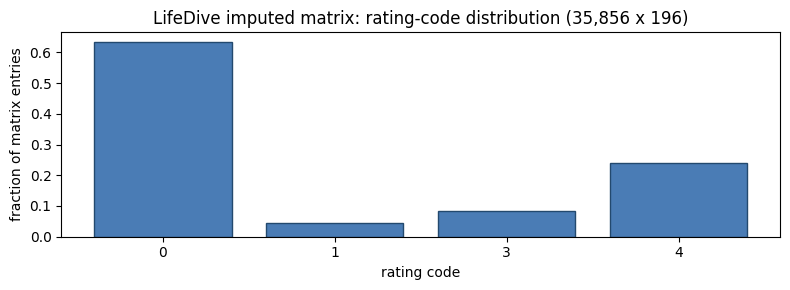

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("/content/lifedive/lifedive_analysis_matrix_imputed_2May2026.csv")
print("shape:", df.shape)
print("first columns:", list(df.columns[:5]), "... last:", list(df.columns[-3:]))
codes = np.unique(df.iloc[:, 1:].to_numpy())
print("distinct item codes:", codes)
print(df.head(3).iloc[:, :8].to_string())

fig, ax = plt.subplots(figsize=(8, 3))
vals, counts = np.unique(df.iloc[:, 1:].to_numpy().ravel(), return_counts=True)
ax.bar([str(v) for v in vals], counts / counts.sum(), color="#4A7CB5", edgecolor="#23496E")
ax.set_xlabel("rating code")
ax.set_ylabel("fraction of matrix entries")
ax.set_title("LifeDive imputed matrix: rating-code distribution (35,856 x 196)")
fig.tight_layout()
fig.savefig("/content/lifedive/input_preview.png", dpi=150)
plt.show()
del df  # free memory before the R stage

## 6. Run the author's factor-analysis script verbatim

Execute `run_factor_analysis.R` unchanged inside a single R process via a minimal wrapper.
The wrapper (clearly marked as added by this notebook, not part of the author code) only
measures elapsed time and saves the fitted `irt.fa` model object for inspection; all
scientific operations come from the author file: recode 3→2 and 4→3, `irt.fa(items, 14,
rotate="promax")` on the polychoric matrix, `scoreIrt` unit-weighted "total" scores, jitter
(seed 2026), dimension renaming, reversal of columns 12/13, winsorize(0.0005)+scale, and
`TEMP_organism_data.csv`.

**著者スクリプトの実行:** `run_factor_analysis.R` をそのまま実行します。ラッパーは
時間計測とモデル保存のみを追加したもので、科学的操作はすべて著者コード由来です。

In [ ]:
import pathlib, subprocess, time

WRAPPER = r'''
# ---- wrapper added by this notebook (AI): timing + model save only ----
t0 <- Sys.time()
source("run_factor_analysis.R")
cat("elapsed_min:", round(as.numeric(difftime(Sys.time(), t0, units = "mins")), 2), "\n")
cat("TEMP_organism_data.csv exists:", file.exists("TEMP_organism_data.csv"), "\n")
saveRDS(mod, "mod.rds")
'''
p = pathlib.Path("/content/lifedive/run_factor_analysis_wrapped.R")
p.write_text(WRAPPER)
t0 = time.time()
res = subprocess.run([RSCRIPT, str(p)], cwd="/content/lifedive",
                     capture_output=True, text=True, timeout=14400)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr[-4000:])
    raise RuntimeError(f"author factor-analysis script failed (exit {res.returncode}).")
print(f"total wall time: {time.time()-t0:.1f} s")

elapsed_min: 17.17 
TEMP_organism_data.csv exists: TRUE 

total wall time: 1030.5 s


## 7. The 14-factor solution — loadings and variance

Summarize the fitted `irt.fa` object: proportion of variance accounted for by the 14 promax-
rotated factors and the strongest loading items per factor. The paper names the dimensions
Plant-like, Fungus-like, Aquatic, Insect-like, Simple, Robust, Durable, Bird-like, Dangerous,
Shelled, Drought-tolerant, Parasitic, Cold-tolerant, Environmentally_Sensitive (author script
line 20); we display loadings and check whether the top items plausibly match those labels —
a plausibility check, not a full-paper equivalence claim.

**14 因子解の要約:** 回転後負荷量と説明分散、各因子の上位項目を表示します。因子名と
上位項目の整合性は妥当性の確認であり、論文全体の同等性証明ではありません。

In [ ]:
r_snippet = r'''
library(psych)
mod <- readRDS("/content/lifedive/mod.rds")
fa_load <- fa.sort(mod$fa$loadings)
write.csv(unclass(fa_load), "/content/lifedive/loadings_sorted.csv", na = "")
cat("Proportion of variance accounted for by the 14 factors:\n")
print(round(mod$fa$Vaccounted, 3))
cat("\nTop 5 loading items per factor (MR1..MR14):\n")
L <- unclass(fa_load)
for (f in colnames(L)) {
  top <- names(sort(abs(L[, f]), decreasing = TRUE)[1:5])
  cat(f, ": ", paste(top, collapse = ", "), "\n")
}
'''
res = subprocess.run([RSCRIPT, "-e", r_snippet], capture_output=True, text=True, timeout=600)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr[-3000:])
    raise RuntimeError(f"loadings inspection failed (exit {res.returncode}).")

Proportion of variance accounted for by the 14 factors:
                         MR1    MR4    MR3    MR2   MR7   MR6  MR10   MR8   MR5
SS loadings           47.456 11.413 10.708 10.501 7.031 6.422 6.171 5.499 3.841
Proportion Var         0.242  0.058  0.055  0.054 0.036 0.033 0.031 0.028 0.020
Cumulative Var         0.242  0.300  0.355  0.409 0.444 0.477 0.509 0.537 0.556
Proportion Explained   0.382  0.092  0.086  0.085 0.057 0.052 0.050 0.044 0.031
Cumulative Proportion  0.382  0.474  0.561  0.645 0.702 0.754 0.803 0.848 0.879
                       MR11  MR14   MR9  MR12  MR13
SS loadings           3.594 3.186 3.022 2.783 2.467
Proportion Var        0.018 0.016 0.015 0.014 0.013
Cumulative Var        0.575 0.591 0.606 0.621 0.633
Proportion Explained  0.029 0.026 0.024 0.022 0.020
Cumulative Proportion 0.908 0.933 0.958 0.980 1.000

Top 5 loading items per factor (MR1..MR14):
MR1 :  Does.this.organism.produce.cellulose., Does.this.organism.exhibit.etiolation.or.similar.responses.to

## 8. Score table produced by the author script

The author script wrote `TEMP_organism_data.csv` (organism + 14 dimensions; jittered,
reversed, winsorized, standardized — the paper states these scores were "not intended for
release" and are for graphing). We show its shape, a few rows, and per-dimension summaries.

**スコアテーブル:** 著者スクリプトが出力した `TEMP_organism_data.csv` の形状・先頭行・
次元別要約統計を表示します（ジッター付き・作図用スコアである点に注意）。

In [ ]:
sc = pd.read_csv("/content/lifedive/TEMP_organism_data.csv")
print("shape:", sc.shape)
print("columns:", list(sc.columns))
print(sc.head(5).to_string())
display(sc.iloc[:, 1:].describe().round(3))
sc.to_csv("/content/lifedive/TEMP_organism_data_copy.csv", index=False)

shape: (35856, 15)
columns: ['x...1.', 'Plant.like', 'Fungus.like', 'Aquatic', 'Insect.like', 'Simple', 'Robust', 'Durable', 'Bird.like', 'Dangerous', 'Shelled', 'Drought.tolerant', 'Parasitic', 'Cold.tolerant', 'Environmentally_Sensitive']
                                        x...1.  Plant.like  Fungus.like   Aquatic  Insect.like    Simple    Robust   Durable  Bird.like  Dangerous   Shelled  Drought.tolerant  Parasitic  Cold.tolerant  Environmentally_Sensitive
0  Aaptosyax grypus (Mekong Giant Salmon Carp)   -0.412727     0.055978  1.219033    -1.148517 -0.862445 -0.912751  1.886018   0.282327  -0.715744 -1.181583         -1.118451   1.225255       0.228213                   2.602770
1                        Aaraecoryphe hermanni   -0.334306     0.218413  1.046308     0.834831 -1.381672 -1.332969  1.845788  -1.242585  -1.391315  1.403666         -0.919676   0.212325      -0.007598                  -0.938558
2                               Abacion magnum   -0.322066     0.300359 -0.

,Plant.like,Fungus.like,Aquatic,Insect.like,Simple,Robust,Durable,Bird.like,Dangerous,Shelled,Drought.tolerant,Parasitic,Cold.tolerant,Environmentally_Sensitive
count,35856.000,35856.000,35856.000,35856.000,35856.000,35856.000,35856.000,35856.000,35856.000,35856.000,35856.000,35856.000,35856.000,35856.000
mean,0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,0.000,0.000,0.000,-0.000,-0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-1.173,-1.482,-2.074,-2.268,-1.856,-2.035,-2.291,-2.358,-1.584,-1.457,-1.275,-2.204,-2.412,-2.088
25%,-0.656,-0.486,-0.807,-0.866,-0.679,-0.654,-0.693,-0.734,-0.738,-0.736,-0.916,-0.583,-0.788,-0.713
50%,-0.427,-0.198,-0.181,0.191,-0.209,-0.177,-0.143,-0.069,-0.217,-0.006,-0.190,-0.334,-0.170,-0.096
75%,0.117,0.146,0.966,0.802,0.451,0.427,0.544,0.640,0.511,0.612,0.614,0.192,0.804,0.629
max,2.766,6.127,2.098,2.027,4.838,4.289,4.658,3.543,4.597,3.520,3.751,4.945,3.531,3.341


## 9. Additional visualization: loading heatmap

A heatmap of the 196 × 14 sorted pattern coefficients (this figure is **created by this
notebook**, it is not a paper figure). Bold |loading| ≥ 0.5 blocks should appear near the
diagonal if the promax solution is cleanly simple-structured; the paper instead notes the
14-factor solution is a descriptive reduction (parallel analysis suggested 58 factors).

**追加可視化:** 196 項目 × 14 因子の負荷量ヒートマップ（本ノートブックで作成した図であり、
論文の図ではありません）。論文は 14 因子を記述的縮約と位置づけています。

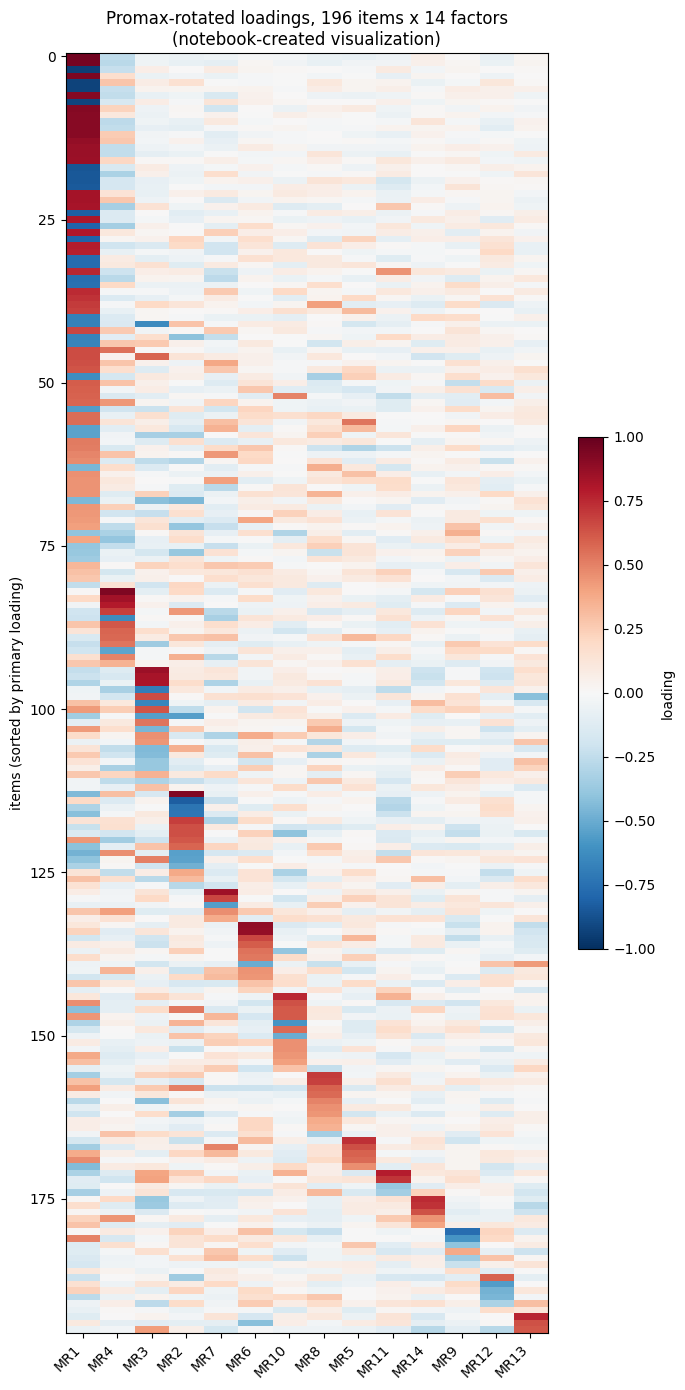

In [ ]:
L = pd.read_csv("/content/lifedive/loadings_sorted.csv", index_col=0)
fig, ax = plt.subplots(figsize=(7, 14))
im = ax.imshow(L.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(L.shape[1]), L.columns, rotation=45, ha="right")
ax.set_ylabel("items (sorted by primary loading)")
ax.set_title("Promax-rotated loadings, 196 items x 14 factors\n(notebook-created visualization)")
fig.colorbar(im, ax=ax, shrink=0.4, label="loading")
fig.tight_layout()
fig.savefig("/content/lifedive/loadings_heatmap.png", dpi=150)
plt.show()

## 10. Reproduce the paper's Figure 2: organism network by phylum

Run the author's `create_n200_network_diagram.R` **verbatim**. It reads the 200-species
validation sample (`lifedive_val.csv`) plus its taxonomy orders, transposes to an organism ×
question matrix, computes polychoric profile similarities (`psych::polychoric`), zeroes
negative similarities, and draws a spring-layout `qgraph` grouped by phylum
(paper Figure 2: "Edges represent positive polychoric profile similarities..."). We convert
the author's PDF output to PNG for display; conversion is an added display step, not a
change to the computation.

**論文 Figure 2 の再現:** 著者の `create_n200_network_diagram.R` をそのまま実行し、
門（phylum）ごとに色分けされたスプリングレイアウトのネットワーク図を PDF→PNG 変換で表示します。

In [ ]:
import pathlib, shutil, subprocess, time

t0 = time.time()
res = subprocess.run([RSCRIPT, "create_n200_network_diagram.R"], cwd="/content/lifedive",
                     capture_output=True, text=True, timeout=3600)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr[-4000:])
    raise RuntimeError(f"author network script failed (exit {res.returncode}).")
print(f"network wall time: {time.time()-t0:.1f} s")

pdf = pathlib.Path("/content/lifedive/organism_network.pdf")
if not pdf.exists() or pdf.stat().st_size < 1000:
    raise RuntimeError("organism_network.pdf missing or implausibly small.")
png = pathlib.Path("/content/lifedive/organism_network.png")
if not shutil.which("pdftoppm"):
    subprocess.run(["apt-get", "update", "-qq"], check=True, timeout=600)
    subprocess.run(["apt-get", "install", "-y", "-qq", "poppler-utils"],
                   check=True, timeout=900)
if not shutil.which("pdftoppm"):
    raise RuntimeError("pdftoppm unavailable even after poppler-utils install.")
conv = subprocess.run(["pdftoppm", "-png", "-r", "110", "-singlefile",
                       str(pdf), str(png.with_suffix(""))],
                      capture_output=True, text=True, timeout=300)
if conv.returncode != 0 or not png.exists():
    raise RuntimeError(f"pdftoppm conversion failed: {conv.stderr[-500:]}")
print("network PNG:", png.stat().st_size, "bytes")

null device 
          1 

network wall time: 239.9 s


network PNG: 881312 bytes


Display the reproduced network figure. Node colors are phylum groups (author palette
"colorblind"); labels are repelled scientific names. This is the actual output of the
author's script on the released validation sample.

**表示:** 再現したネットワーク図。ノード色は門ごとのグループ、ラベルは学名です
（著者スクリプトの実出力）。

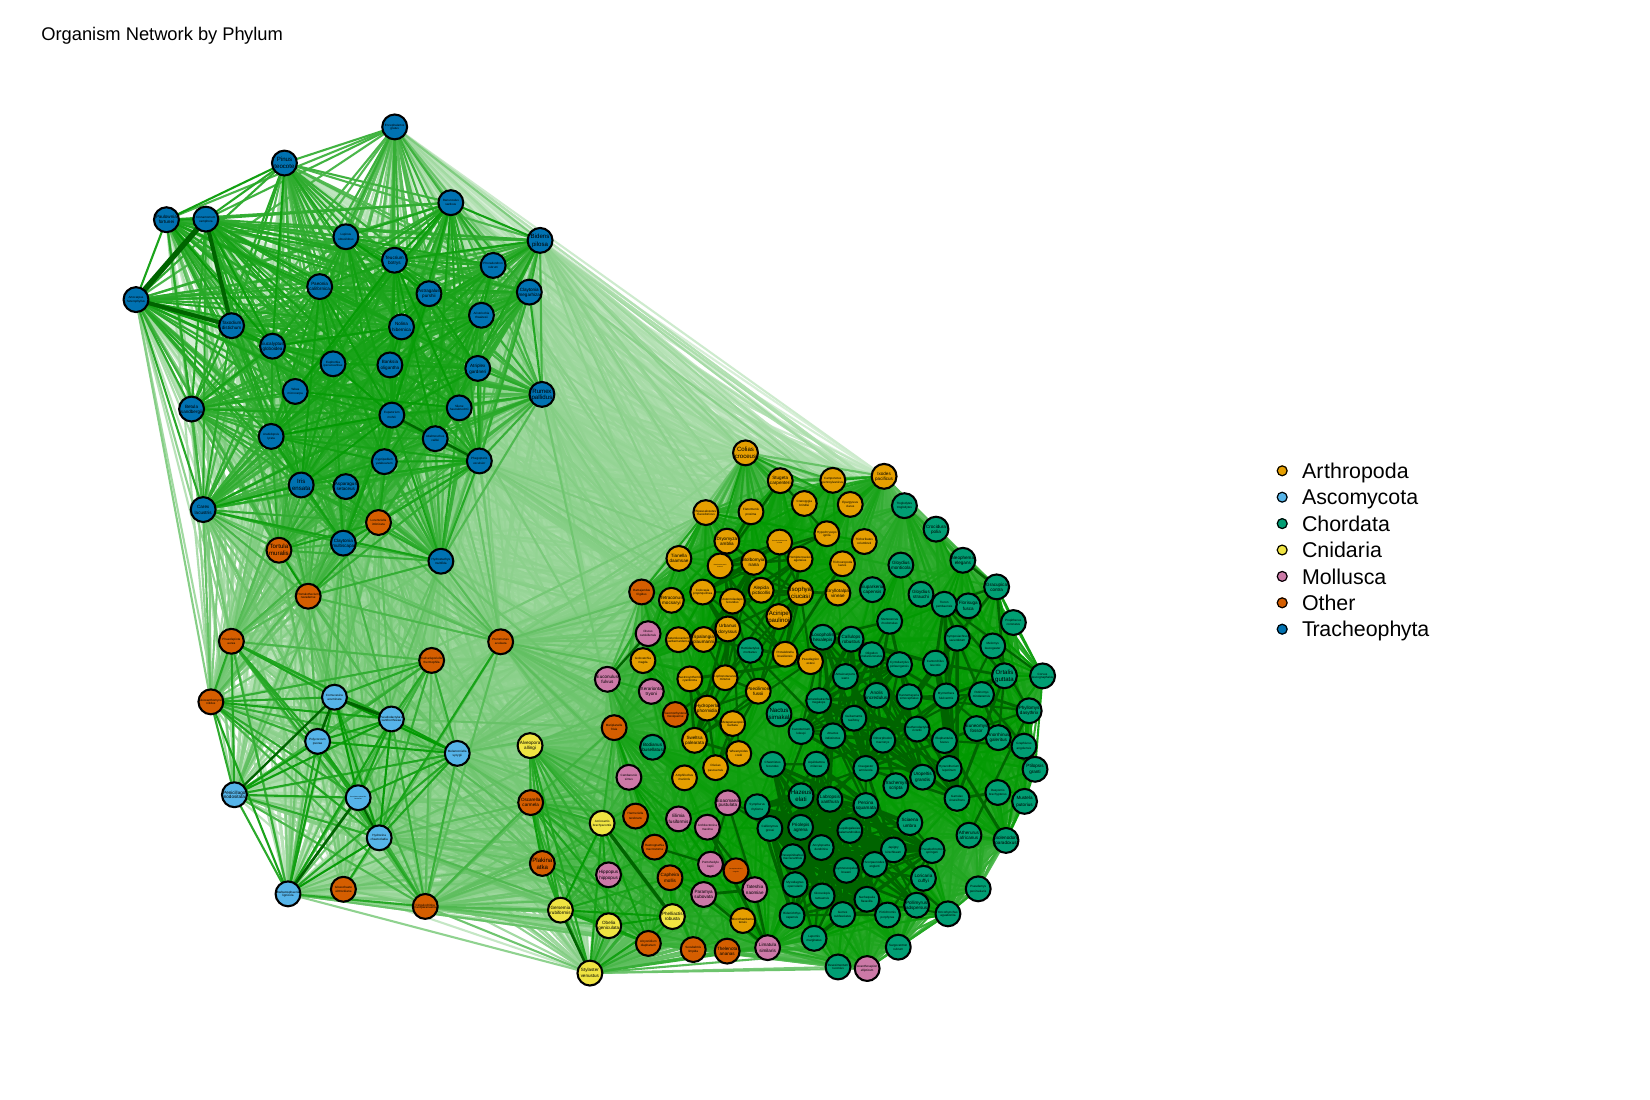

In [ ]:
from IPython.display import Image, display
display(Image(filename="/content/lifedive/organism_network.png"))

## 11. Interpretation and limitations

**What was reproduced (partial demonstration, executed):** the exploratory 14-factor IRT
factor analysis of the released 35,856 × 196 imputed matrix with the author's exact
recoding, rotation, scoring, jitter, reversal, winsorizing, and standardization; and the
paper's Figure 2 network from the released 200-species validation sample — both by running
the author's released R scripts byte-unchanged. One-example/partial scope: this does **not**
verify dataset-level benchmark accuracies, the annotation stage, or imputation quality.

**Known limitations (from the paper itself, §2.5):** the 14-factor solution is a descriptive
choice — parallel analysis suggested 58 factors and MAP 41; the jittered scores are for
graphing and were "not intended for release"; no OSF license/README is published for the
project (reuse terms unverified by us). Colab R/psych versions may differ from the authors'
R 4.6.0 / psych 2.6.5 — printed versions above are authoritative for this run.

**再現内容と限界:** 著者スクリプトを無変更で実行し、14 因子解と Figure 2 相当のネットワークを
再現しました。アノテーション段階・インピュテーション再実行・ベンチマーク検証は対象外です。
14 因子は記述的な選択（parallel analysis は 58 因子を示唆）であり、ジッター付きスコアは
作図専用です。OSF プロジェクトにはライセンス表記がありません。

## Validation record and references

- **Executed:** `{public_id}.ipynb` via Colab CLI on a fresh **CPU** runtime (validation date
  recorded in the run report). All downloads and computation happened inside this notebook.
- **Paper:** Moore, T. M. (2026). LifeDive: Cross-kingdom phenotype estimates for 35,856
  species. PsyArXiv/OSF preprint, DOI 10.31234/osf.io/64z58.
- **Code:** OSF project aqkhn — `run_factor_analysis.R` (file z2wps, 1091 B),
  `create_n200_network_diagram.R` (file 6a1668566df8af12c8cc7324, 2138 B), accessed 2026-11-15.
- **Data:** `lifedive_analysis_matrix_imputed_2May2026.csv` (15,516,015 B),
  `lifedive_val.csv` (100,618 B), `lifedive_val_orders.csv` (29,927 B), OSF project aqkhn.
- **Packages:** psych, qgraph, igraph (versions printed at install; authors used R 4.6.0,
  psych 2.6.5, ggplot2 4.0.3, ggrepel 0.9.8, patchwork 1.3.2).
- Japanese summary: 本ノートブックは LifeDive（35,856 種 × 196 表現型質問）の公開行列に対し、
  著者公開 R スクリプトをそのまま実行して 14 因子解とスコア作成、および 200 種検証サンプルの
  ポリコリック類似性ネットワーク（論文 Figure 2 相当）を再現する部分再現です。
